### Importing libraries

In [24]:
import cv2
import os
import glob
import matplotlib.pyplot as plt
import numpy as np
import re
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr

In [25]:
# Loads all .jpg images from a folder, sorted numerically by filename
def load_images_from_folder(folder_path, gray=False, n=None):
    images = {}
    
    paths = sorted(glob.glob(os.path.join(folder_path, "*.jpg")), 
                   key=lambda x: int(re.search(r'\d+', os.path.basename(x)).group()))
    
    for img_path in paths[:n]:
        img_name = os.path.basename(img_path)
        img = cv2.imread(img_path)
        images[img_name] = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) if gray else img
    return images


In [26]:
coin_dataset_path = './coin_dataset'
reference_images = load_images_from_folder(os.path.join(coin_dataset_path, 'reference_set'), True)
target_images = load_images_from_folder(os.path.join(coin_dataset_path, 'target_set'), True)


print(f"Loaded {len(reference_images)} images from reference_set")
print(f"Loaded {len(target_images)} images from target_set")

Loaded 8 images from reference_set
Loaded 142 images from target_set


### Denoising exploration
In order to select a pool of denoising methods for which makes sense search for the optimal parameters, we will measure how the denoised image behaves in terms of the $PSNR$ and $SSIM$.

When comparing images, the mean squared error (MSE)–while simple to implement–is not highly indicative of perceived similarity. Structural similarity aims to address this shortcoming by taking texture into account.

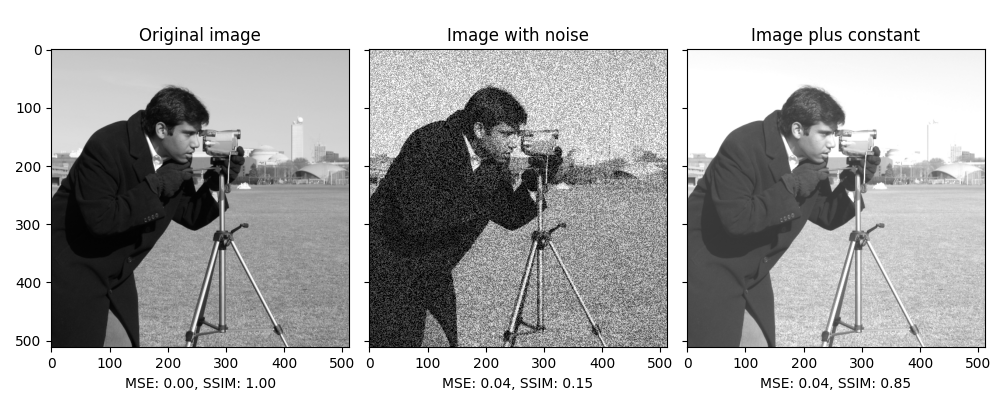
<figcaption align = "center">
<a href="https://scikit-image.org/docs/0.25.x/auto_examples/transform/plot_ssim.html">
https://scikit-image.org/docs/0.25.x/auto_examples/transform/plot_ssim.html
</a>
</figcaption>

Another useful metric since we don't know the source generating noise in the images is the *peak-signal-noise-ratio*.

In [27]:
nlm  = lambda img, h: cv2.fastNlMeansDenoising(img, h=h, templateWindowSize=7, searchWindowSize=21)
med  = lambda img, k: cv2.medianBlur(img, k)
bilat = lambda img: cv2.bilateralFilter(img, d=9, sigmaColor=75, sigmaSpace=75)

denoising_methods = {
    # ── Baselines ────────────────────────────────────────────────────────────
    "NLM h=5":               lambda img: nlm(img, 5),
    "NLM h=6":               lambda img: nlm(img, 6),
    "NLM h=7":               lambda img: nlm(img, 7),
    "NLM h=8":               lambda img: nlm(img, 8),
    "NLM h=10":              lambda img: nlm(img, 10),
    "Median 3":              lambda img: med(img, 3),
    "Median 5":              lambda img: med(img, 5),
    "Bilateral":             lambda img: bilat(img),

    # ── Median → NLM  (widget finding: impulse removal before NLM) ──────────
    "Med3 → NLM h=5":        lambda img: nlm(med(img, 3), 5),
    "Med3 → NLM h=6":        lambda img: nlm(med(img, 3), 6),
    "Med3 → NLM h=7":        lambda img: nlm(med(img, 3), 7),
    "Med3 → NLM h=8":        lambda img: nlm(med(img, 3), 8),
    "Med3 → NLM h=10":       lambda img: nlm(med(img, 3), 10),
    "Med5 → NLM h=5":        lambda img: nlm(med(img, 5), 5),
    "Med5 → NLM h=6":        lambda img: nlm(med(img, 5), 6),
    "Med5 → NLM h=7":        lambda img: nlm(med(img, 5), 7),

    # ── NLM → Median  (post-smoothing to clean NLM residuals) ───────────────
    "NLM h=6 → Med3":        lambda img: med(nlm(img, 6), 3),
    "NLM h=8 → Med3":        lambda img: med(nlm(img, 8), 3),
    "NLM h=10 → Med3":       lambda img: med(nlm(img, 10), 3),

    # ── Median → NLM → Median  (sandwich) ───────────────────────────────────
    "Med3 → NLM h=6 → Med3": lambda img: med(nlm(med(img, 3), 6), 3),
    "Med3 → NLM h=8 → Med3": lambda img: med(nlm(med(img, 3), 8), 3),

    # ── Bilateral combos ────────────────────────────────────────────────────
    "Bilat → NLM h=6":       lambda img: nlm(bilat(img), 6),
    "Bilat → NLM h=8":       lambda img: nlm(bilat(img), 8),
    "NLM h=6 → Bilat":       lambda img: bilat(nlm(img, 6)),
    "NLM h=8 → Bilat":       lambda img: bilat(nlm(img, 8)),
    "Med3 → Bilat":          lambda img: bilat(med(img, 3)),
    "Med3 → Bilat → NLM h=6":lambda img: nlm(bilat(med(img, 3)), 6),
}

In [28]:
NOISE_STD = 25
np.random.seed(42)

results = {name: {} for name in denoising_methods}

for img_name, noisy in target_images.items():
    for method_name, fn in denoising_methods.items():
        denoised = fn(noisy)
        results[method_name][img_name] = {
            "denoised": denoised,
            "psnr":     psnr(noisy, denoised),
            "ssim":     ssim(noisy, denoised),
        }

# Mean metrics per method
for method_name in denoising_methods:
    scores = results[method_name]
    mean_p = np.mean([v["psnr"] for v in scores.values()])
    mean_s = np.mean([v["ssim"] for v in scores.values()])
    print(f"{method_name:<20}  PSNR: {mean_p:.2f} dB  SSIM: {mean_s:.4f}")

NLM h=5               PSNR: inf dB  SSIM: 1.0000
NLM h=6               PSNR: 80.05 dB  SSIM: 1.0000
NLM h=7               PSNR: 56.86 dB  SSIM: 0.9996
NLM h=8               PSNR: 42.50 dB  SSIM: 0.9892
NLM h=10              PSNR: 29.79 dB  SSIM: 0.8060
Median 3              PSNR: 23.41 dB  SSIM: 0.3251
Median 5              PSNR: 23.07 dB  SSIM: 0.2253
Bilateral             PSNR: 23.59 dB  SSIM: 0.2887
Med3 → NLM h=5        PSNR: 23.39 dB  SSIM: 0.2616
Med3 → NLM h=6        PSNR: 23.31 dB  SSIM: 0.2431
Med3 → NLM h=7        PSNR: 23.25 dB  SSIM: 0.2304
Med3 → NLM h=8        PSNR: 23.20 dB  SSIM: 0.2211
Med3 → NLM h=10       PSNR: 23.12 dB  SSIM: 0.2086
Med5 → NLM h=5        PSNR: 23.06 dB  SSIM: 0.2020
Med5 → NLM h=6        PSNR: 23.04 dB  SSIM: 0.1976
Med5 → NLM h=7        PSNR: 23.01 dB  SSIM: 0.1941
NLM h=6 → Med3        PSNR: 23.41 dB  SSIM: 0.3251
NLM h=8 → Med3        PSNR: 23.43 dB  SSIM: 0.3188
NLM h=10 → Med3       PSNR: 23.41 dB  SSIM: 0.2762
Med3 → NLM h=6 → Med3  PSNR: 23.2

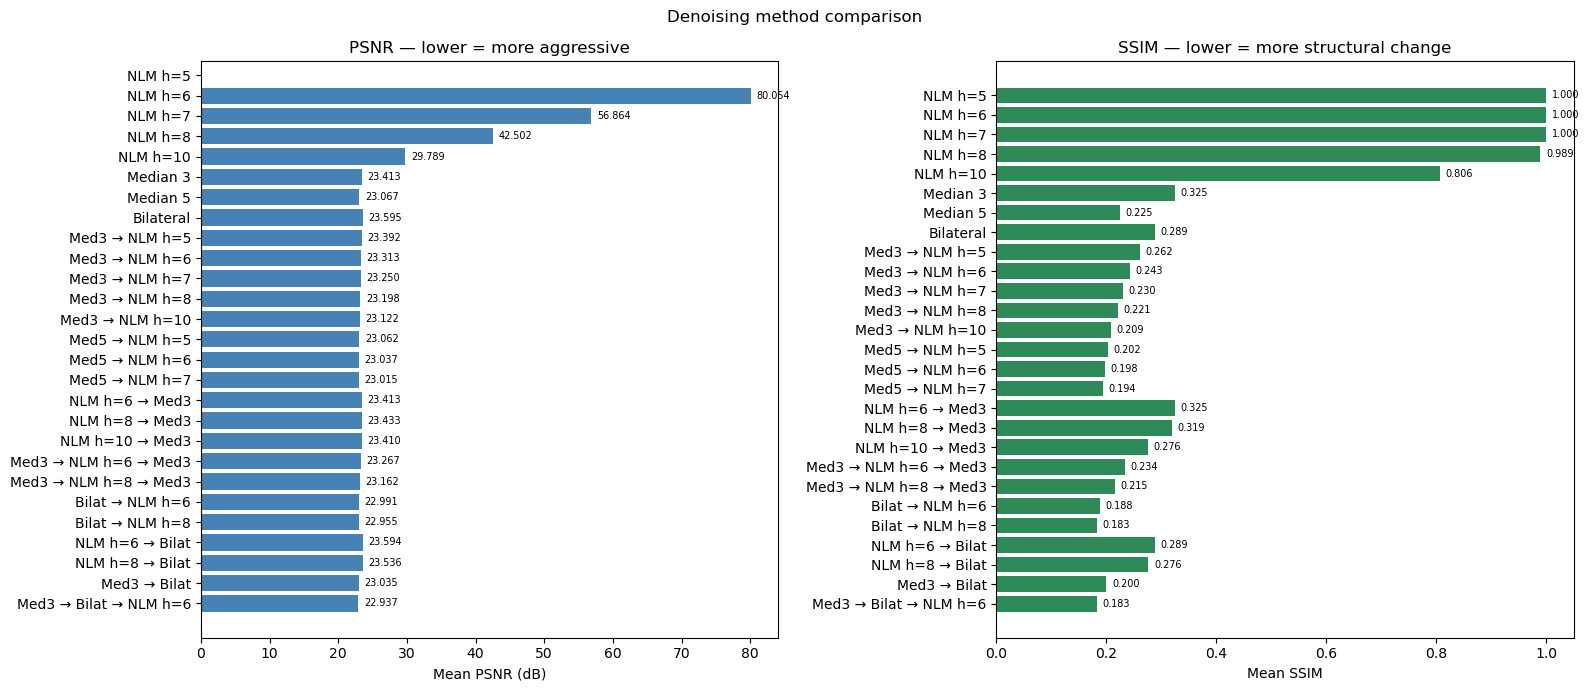

In [29]:
methods = list(results.keys())
means_psnr = [np.mean([results[m][img]["psnr"] for img in results[m]]) for m in methods]
means_ssim = [np.mean([results[m][img]["ssim"] for img in results[m]]) for m in methods]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, values, label, color in zip(
    axes,
    [means_psnr, means_ssim],
    ["Mean PSNR (dB)", "Mean SSIM"],
    ["steelblue", "seagreen"]
):
    bars = ax.barh(methods, values, color=color)
    ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=7)
    ax.set_xlabel(label)
    ax.invert_yaxis()

axes[0].set_title("PSNR — lower = more aggressive")
axes[1].set_title("SSIM — lower = more structural change")
plt.suptitle("Denoising method comparison")
plt.tight_layout()
plt.show()

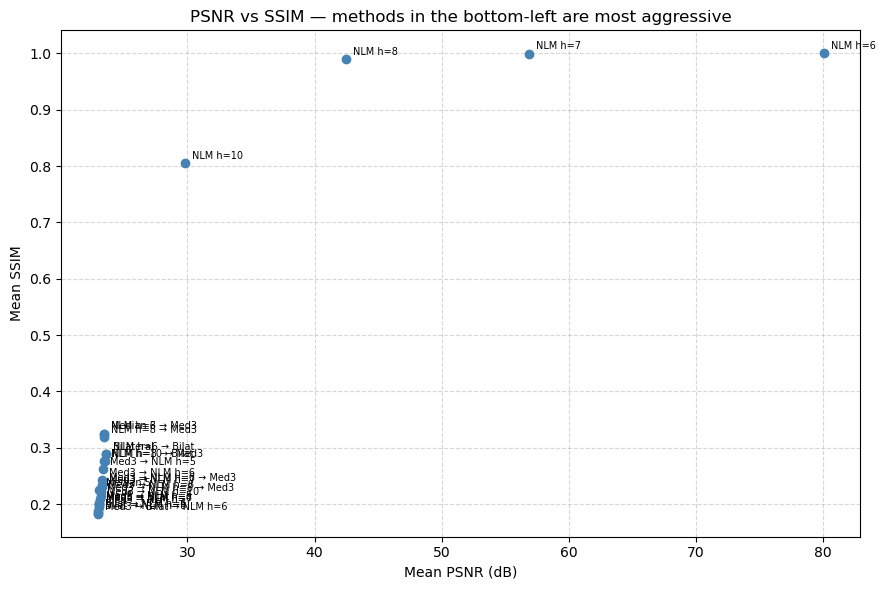

In [30]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(means_psnr, means_ssim, color="steelblue", zorder=3)

for m, x, y in zip(methods, means_psnr, means_ssim):
    ax.annotate(m, (x, y), textcoords="offset points", xytext=(5, 3), fontsize=7)

ax.set_xlabel("Mean PSNR (dB)")
ax.set_ylabel("Mean SSIM")
ax.set_title("PSNR vs SSIM — methods in the bottom-left are most aggressive")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


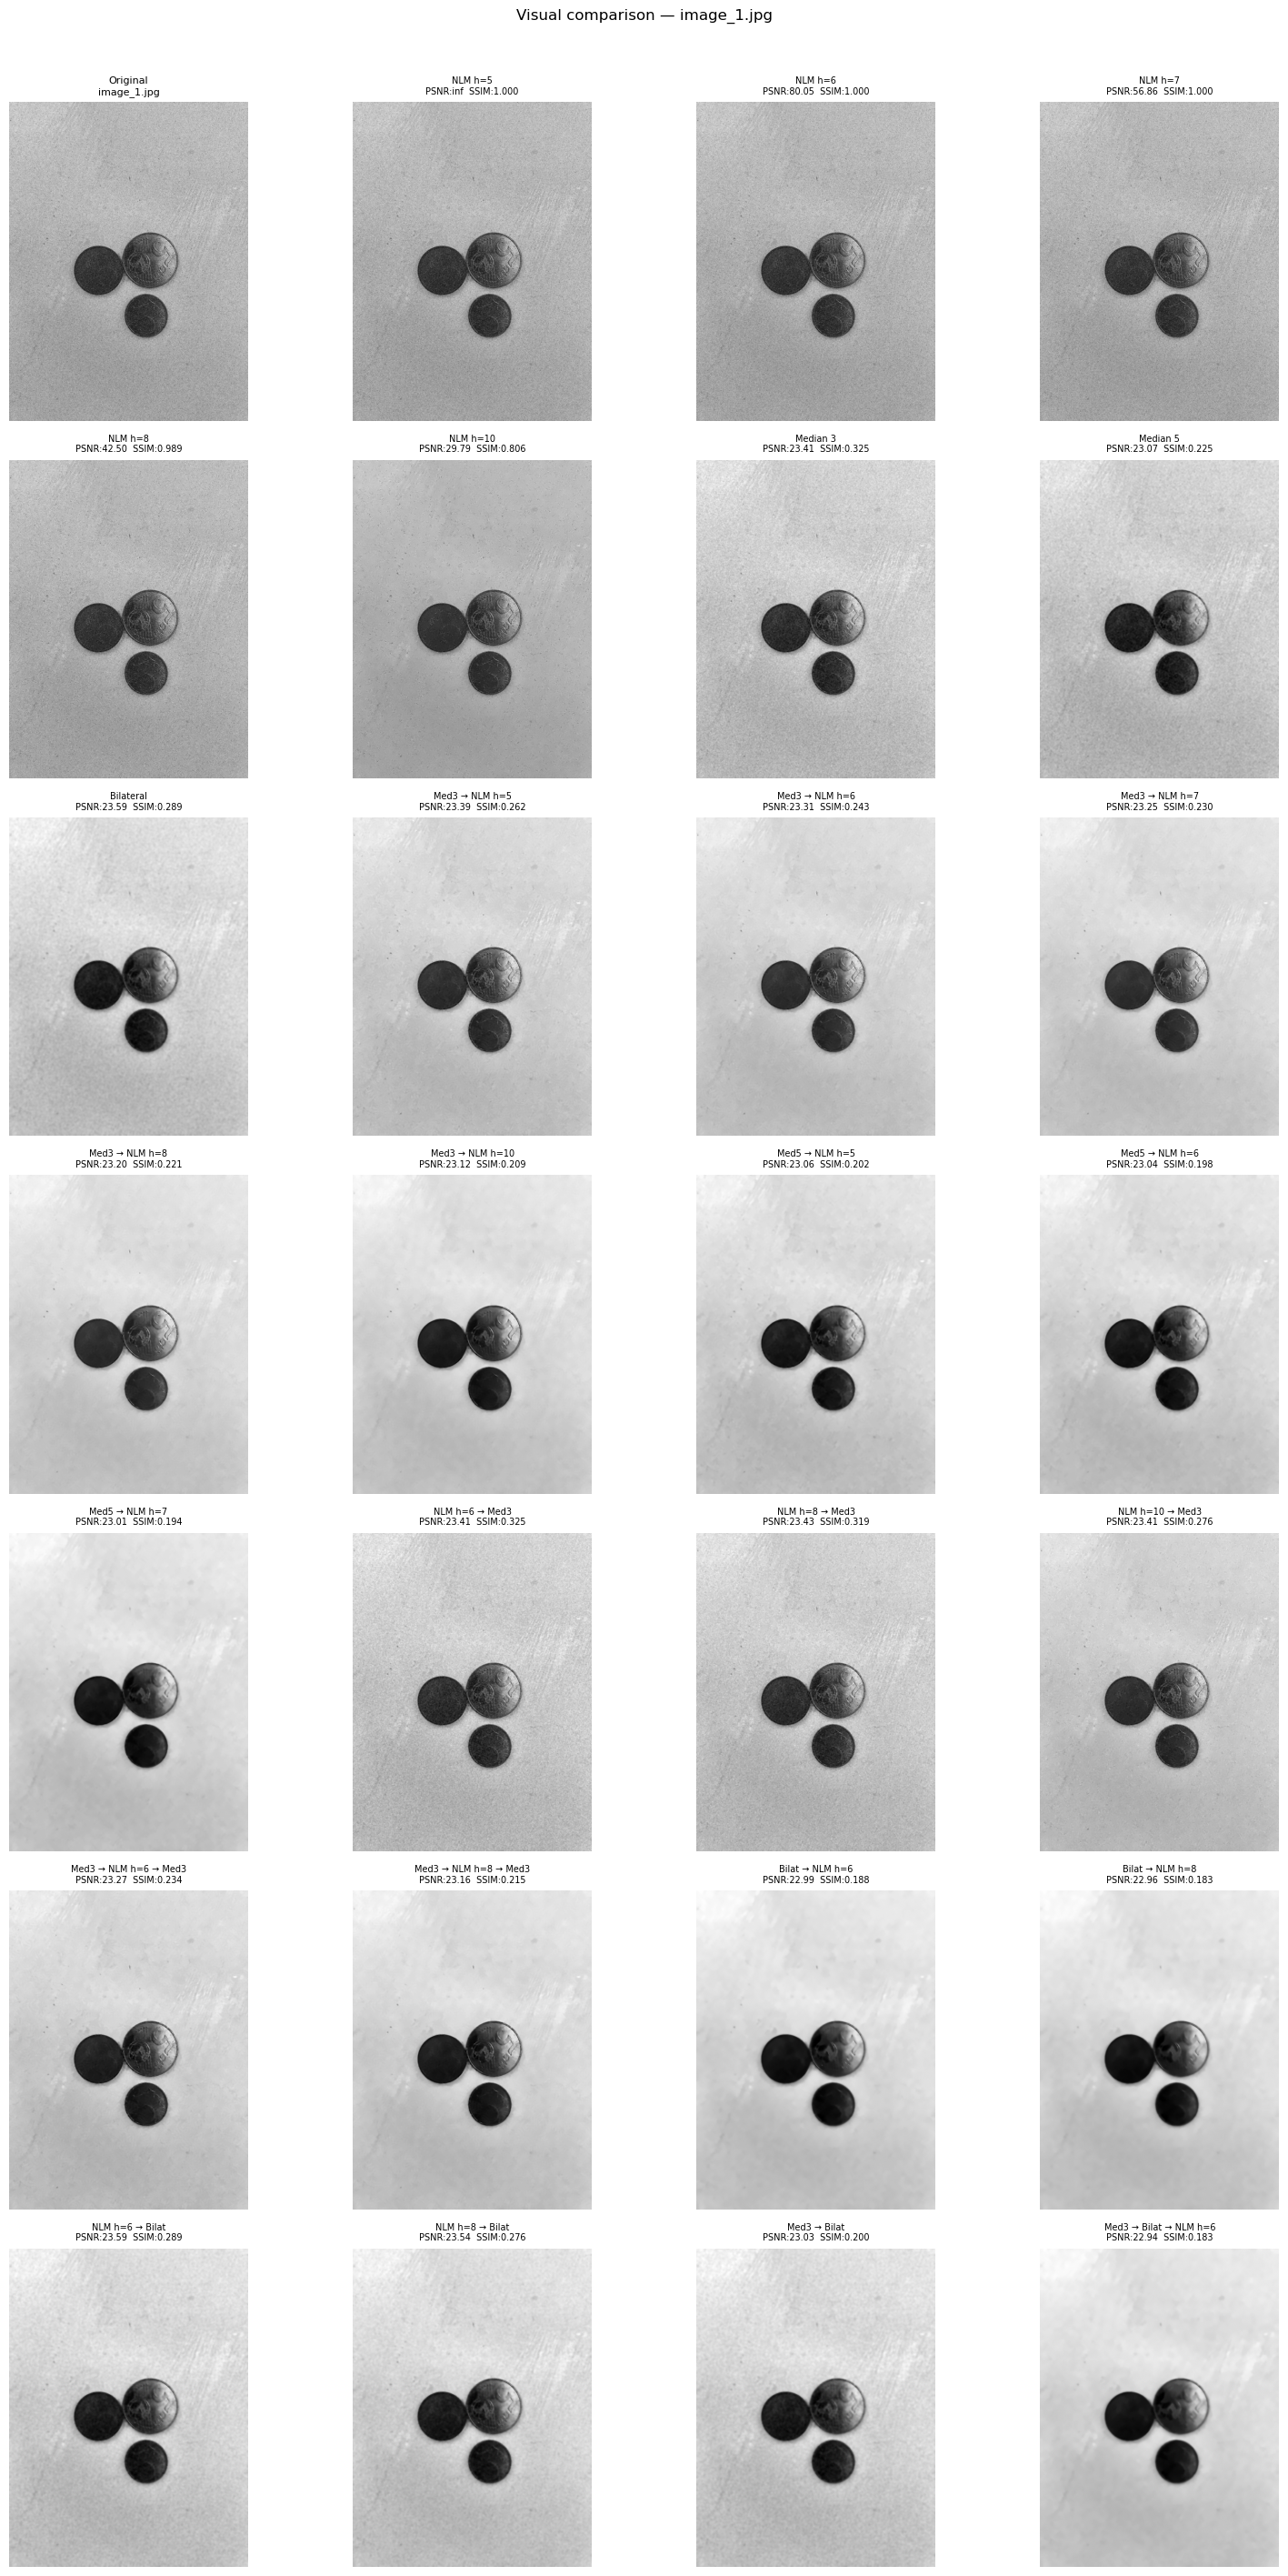

In [31]:
sample_name, sample_img = next(iter(target_images.items()))
n = len(denoising_methods)
cols = 4
rows = (n + 1 + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4))
axes = axes.flatten()

axes[0].imshow(sample_img, cmap="gray")
axes[0].set_title(f"Original\n{sample_name}", fontsize=8)
axes[0].axis("off")

for i, (method_name, fn) in enumerate(denoising_methods.items(), start=1):
    p = np.mean([results[method_name][img]["psnr"] for img in results[method_name]])
    s = np.mean([results[method_name][img]["ssim"] for img in results[method_name]])
    denoised = results[method_name][sample_name]["denoised"]
    axes[i].imshow(denoised, cmap="gray")
    axes[i].set_title(f"{method_name}\nPSNR:{p:.2f}  SSIM:{s:.3f}", fontsize=7)
    axes[i].axis("off")

for ax in axes[n + 1:]:
    ax.axis("off")

plt.suptitle(f"Visual comparison — {sample_name}", y=1.01)
plt.tight_layout()
plt.show()


### SIFT-based Evaluation

Two metrics are used to assess denoising quality via feature matching:

1. **% KPs matched** — ratio of matched keypoints to total model keypoints (higher = better)
2. **Mean descriptor distance** — Euclidean distance between matched SIFT descriptors (lower = better)

A **final score** combines z-score normalized versions of both, weighting descriptor quality more heavily:

$$\text{Final Score} = 0.6 \cdot \left(-z_{\text{dist}}\right) + 0.4 \cdot z_{\text{match\%}}$$

*Evaluation pairs: each reference coin image is used as the model; a synthetic noisy version (Gaussian noise, σ=25) is used as the scene.*

In [32]:
import math

sift  = cv2.SIFT_create()
flann = cv2.FlannBasedMatcher(dict(algorithm=1, trees=5), dict(checks=50))

def get_good_matches(des1, des2, threshold=0.7):
    if des1 is None or des2 is None or len(des1) < 2 or len(des2) < 2:
        return []
    return [m for m, n in flann.knnMatch(des1, des2, k=2) if m.distance < threshold * n.distance]

def compute_homography(kp1, kp2, good_matches):
    if len(good_matches) < 4:
        return None
    src = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    M, _ = cv2.findHomography(src, dst, cv2.RANSAC, 10.0)
    return M

def extract_roi(model, scene, M):
    return cv2.warpPerspective(scene, np.linalg.inv(M), (model.shape[1], model.shape[0]))

def sift_match_metrics(model_kp, model_des, roi):
    """Match model descriptors against ROI; return (%KPs matched, mean descriptor distance)."""
    roi_kp, roi_des = sift.detectAndCompute(roi, None)
    good = get_good_matches(model_des, roi_des)
    pct_kps   = len(good) / len(model_kp) * 100 if model_kp else 0.0
    mean_dist = np.mean([m.distance for m in good]) if good else np.nan
    return pct_kps, mean_dist

In [33]:
# Manually verified ground-truth pairs (solo coins only)
eval_pairs = {
    "10cent.jpg": ["image_2.jpg", "image_5.jpg", "image_10.jpg", "image_93.jpg", "image_131.jpg", "image_135.jpg"],
    "1cent.jpg":  ["image_4.jpg", "image_64.jpg"],
    "20cent.jpg": ["image_6.jpg", "image_14.jpg", "image_35.jpg", "image_56.jpg", "image_83.jpg"],
}

# Load only the required target scenes as grayscale
target_scenes = {
    name: cv2.imread(os.path.join(coin_dataset_path, "target_set", name), cv2.IMREAD_GRAYSCALE)
    for names in eval_pairs.values() for name in names
}

# Precompute model keypoints once (they don't change across denoising methods)
model_kpdes = {
    ref_name: sift.detectAndCompute(reference_images[ref_name], None)
    for ref_name in eval_pairs
}

sift_results = {name: {"pct_kps": [], "mean_dist": []} for name in denoising_methods}

for method_name, fn in denoising_methods.items():
    for ref_name, scene_names in eval_pairs.items():
        model_img          = reference_images[ref_name]
        model_kp, model_des = model_kpdes[ref_name]

        for scene_name in scene_names:
            denoised = fn(target_scenes[scene_name])

            # Homography: model → denoised scene
            scene_kp, scene_des = sift.detectAndCompute(denoised, None)
            good = get_good_matches(model_des, scene_des)
            M = compute_homography(model_kp, scene_kp, good)

            if M is None:
                print(f"  [skip] {method_name} | {ref_name} → {scene_name}: homography failed")
                continue

            roi = extract_roi(model_img, denoised, M)
            pct, dist = sift_match_metrics(model_kp, model_des, roi)
            sift_results[method_name]["pct_kps"].append(pct)
            sift_results[method_name]["mean_dist"].append(dist)

print("Done.")

  [skip] NLM h=5 | 10cent.jpg → image_2.jpg: homography failed
  [skip] NLM h=5 | 10cent.jpg → image_5.jpg: homography failed
  [skip] NLM h=5 | 10cent.jpg → image_10.jpg: homography failed
  [skip] NLM h=5 | 10cent.jpg → image_93.jpg: homography failed
  [skip] NLM h=5 | 10cent.jpg → image_131.jpg: homography failed
  [skip] NLM h=5 | 10cent.jpg → image_135.jpg: homography failed
  [skip] NLM h=5 | 1cent.jpg → image_4.jpg: homography failed
  [skip] NLM h=5 | 1cent.jpg → image_64.jpg: homography failed
  [skip] NLM h=5 | 20cent.jpg → image_14.jpg: homography failed
  [skip] NLM h=5 | 20cent.jpg → image_35.jpg: homography failed
  [skip] NLM h=5 | 20cent.jpg → image_56.jpg: homography failed
  [skip] NLM h=6 | 10cent.jpg → image_2.jpg: homography failed
  [skip] NLM h=6 | 10cent.jpg → image_5.jpg: homography failed
  [skip] NLM h=6 | 10cent.jpg → image_10.jpg: homography failed
  [skip] NLM h=6 | 10cent.jpg → image_93.jpg: homography failed
  [skip] NLM h=6 | 10cent.jpg → image_131.jpg

Method                        Score     %KPs   MeanDist
--------------------------------------------------------
NLM h=5                         nan     1.69     151.81
NLM h=6                         nan     1.69     151.81
NLM h=7                         nan     6.09     130.96
NLM h=8                         nan     8.47     133.81
NLM h=10                        nan      nan        nan
Median 3                        nan     0.00        nan
Median 5                        nan      nan        nan
Bilateral                       nan     0.00        nan
Med3 → NLM h=5                  nan     0.64     193.55
Med3 → NLM h=6                  nan     1.27     205.92
Med3 → NLM h=7                  nan     0.00        nan
Med3 → NLM h=8                  nan     0.00        nan
Med3 → NLM h=10                 nan     3.23     221.80
Med5 → NLM h=5                  nan      nan        nan
Med5 → NLM h=6                  nan      nan        nan
Med5 → NLM h=7                  nan      nan   

/var/folders/fq/nxzk17vn0nn9vtfhdlcrzqj00000gn/T/ipykernel_22414/2505506282.py:3: RuntimeWarning: Mean of empty slice
  avg_pct  = np.array([np.nanmean(sift_results[m]["pct_kps"])   for m in methods])
/var/folders/fq/nxzk17vn0nn9vtfhdlcrzqj00000gn/T/ipykernel_22414/2505506282.py:4: RuntimeWarning: Mean of empty slice
  avg_dist = np.array([np.nanmean(sift_results[m]["mean_dist"]) for m in methods])
/var/folders/fq/nxzk17vn0nn9vtfhdlcrzqj00000gn/T/ipykernel_22414/2505506282.py:24: RuntimeWarning: Mean of empty slice
  ranked_pct     = [np.nanmean(sift_results[m]["pct_kps"])   for m in ranked_methods]
/var/folders/fq/nxzk17vn0nn9vtfhdlcrzqj00000gn/T/ipykernel_22414/2505506282.py:25: RuntimeWarning: Mean of empty slice
  ranked_dist    = [np.nanmean(sift_results[m]["mean_dist"]) for m in ranked_methods]


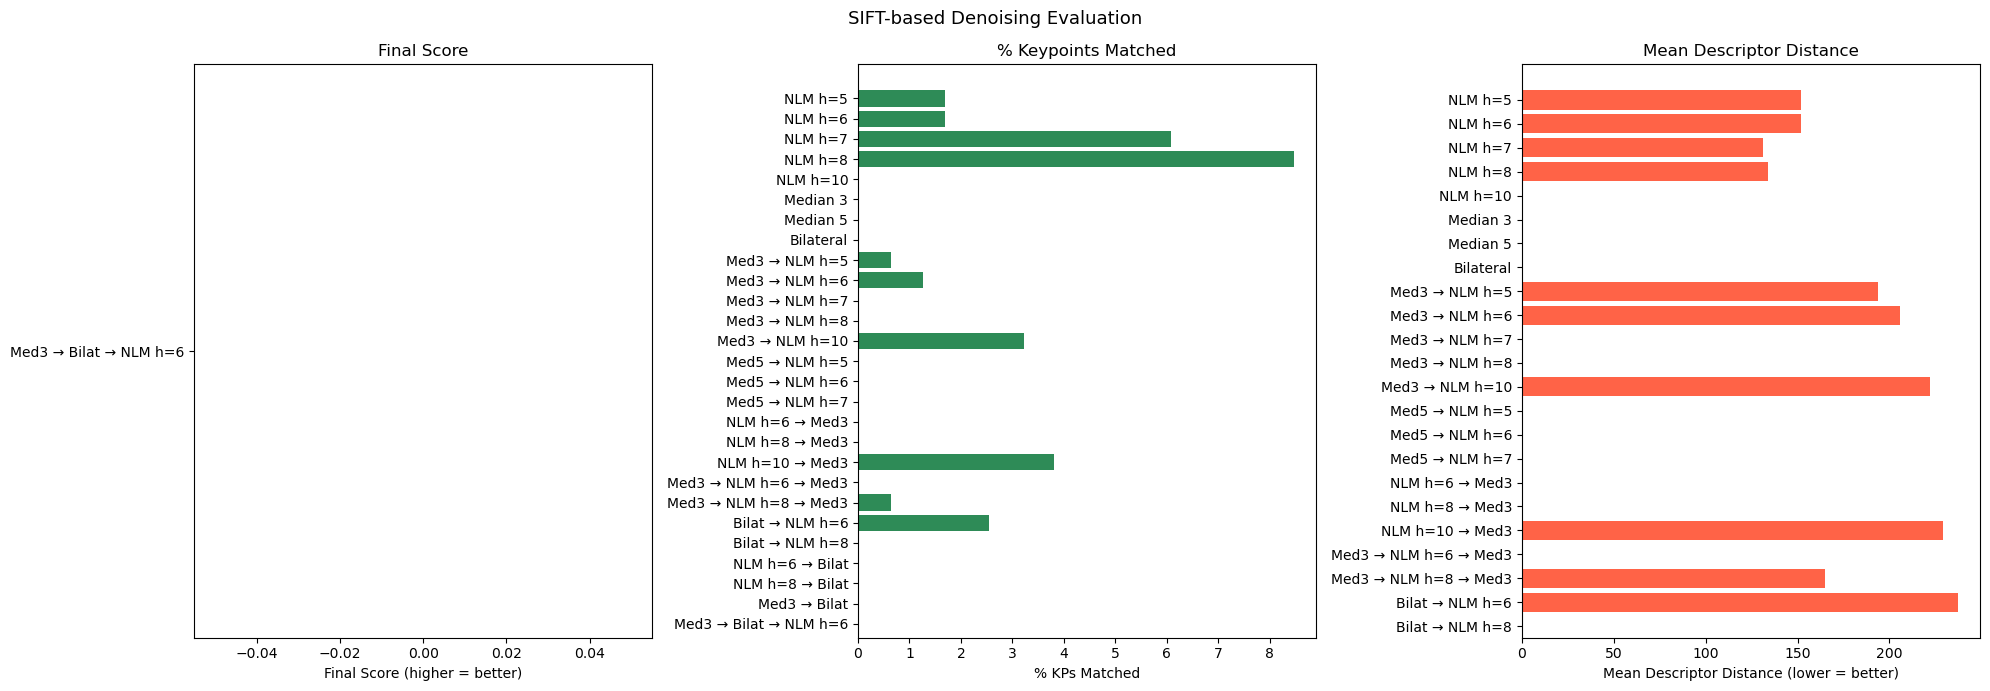

In [34]:
methods = list(denoising_methods.keys())

avg_pct  = np.array([np.nanmean(sift_results[m]["pct_kps"])   for m in methods])
avg_dist = np.array([np.nanmean(sift_results[m]["mean_dist"]) for m in methods])

# Z-score normalize
z_pct  = (avg_pct  - avg_pct.mean())  / (avg_pct.std()  + 1e-8)
z_dist = (avg_dist - avg_dist.mean()) / (avg_dist.std() + 1e-8)

# Combine: invert distance (lower is better) and weight 0.6 / 0.4
w1, w2 = 0.6, 0.4
final_scores = w1 * (-z_dist) + w2 * z_pct

ranking = sorted(zip(methods, final_scores, avg_pct, avg_dist), key=lambda x: -x[1])

print(f"{'Method':<26} {'Score':>8} {'%KPs':>8} {'MeanDist':>10}")
print("-" * 56)
for m, score, pct, dist in ranking:
    print(f"{m:<26} {score:>8.4f} {pct:>8.2f} {dist:>10.2f}")

# ── Plots ────────────────────────────────────────────────────────────────────
ranked_methods = [x[0] for x in ranking]
ranked_scores  = [x[1] for x in ranking]
ranked_pct     = [np.nanmean(sift_results[m]["pct_kps"])   for m in ranked_methods]
ranked_dist    = [np.nanmean(sift_results[m]["mean_dist"]) for m in ranked_methods]

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

axes[0].barh(ranked_methods[::-1], ranked_scores[::-1],  color="steelblue")
axes[0].set_xlabel("Final Score (higher = better)")
axes[0].set_title("Final Score")

axes[1].barh(ranked_methods[::-1], ranked_pct[::-1],    color="seagreen")
axes[1].set_xlabel("% KPs Matched")
axes[1].set_title("% Keypoints Matched")

axes[2].barh(ranked_methods[::-1], ranked_dist[::-1],   color="tomato")
axes[2].set_xlabel("Mean Descriptor Distance (lower = better)")
axes[2].set_title("Mean Descriptor Distance")

plt.suptitle("SIFT-based Denoising Evaluation", fontsize=13)
plt.tight_layout()
plt.show()